# V16 Autoencoder testing — all-column Data_V3
Loads frozen V16 models, takes all unknown attack records and samples an equal number of BENIGN known-test records. Compares global vs port/group/global thresholds. No retraining.

In [ ]:
from pathlib import Path
import sys, json, random
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report)
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if not (ROOT/'data'/'processed').exists():
    raise FileNotFoundError('Run from the project root or notebooks folder')
sys.path.insert(0,str(ROOT/'notebooks'))
from autoencoder_v16_all_columns_common import (
    VERSION, UNKNOWN, add_behavioural_features, BEHAVIOURAL_FEATURES, validate_frame, fit_preprocessing, transform,
    ports, reconstruction_mse, calibrate, local_thresholds)
DATA_DIR=ROOT/'data'/'processed'/'Data_V3_full'
MODEL_DIR=ROOT/'saved-models'/(VERSION+'_behavioural')
RESULTS_DIR=ROOT/'outputs'/'results'/(VERSION+'_behavioural')
MODEL_DIR.mkdir(parents=True,exist_ok=True)
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
SEED=42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

def load_csv(name):
    csv=DATA_DIR/(name+'.csv'); parquet=DATA_DIR/(name+'.parquet')
    if parquet.exists() and (not csv.exists() or parquet.stat().st_mtime>csv.stat().st_mtime):
        print('Converting',parquet.name,'to CSV')
        pd.read_parquet(parquet).to_csv(csv,index=False)
    if not csv.exists(): raise FileNotFoundError(f'Missing CSV/Parquet for {name}')
    df=pd.read_csv(csv,low_memory=False)
    print(name,df.shape)
    return validate_frame(df,name)


In [3]:
selection=json.loads((MODEL_DIR/'selection.json').read_text())
prep=joblib.load(MODEL_DIR/'preprocessing.joblib')
calibration=json.loads((MODEL_DIR/selection['calibration_file']).read_text())
models=[tf.keras.models.load_model(MODEL_DIR/f) for f in selection['model_files']]
if prep['columns']!=selection['features'] or any(m.input_shape[-1]!=prep['input_dim'] for m in models):
    raise ValueError('Saved model / feature schema mismatch')
print('Models loaded:',len(models),'input dimension:',prep['input_dim'])

print('Using saved training feature order:', prep['columns'])
print('Excluded fields:', prep.get('excluded_fields'))


Models loaded: 3 input dimension: 86
Using saved training feature order: ['Src Port', 'Dst Port', 'Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH F

In [4]:
known=load_csv('known_test')
unknown=load_csv('unknown_test')
assert not known['Label'].isin(UNKNOWN).any()
assert unknown['Label'].isin(UNKNOWN).all()
# Compute causal historical counts BEFORE balancing, over all test flows.
full=add_behavioural_features(pd.concat([known,unknown],ignore_index=True))
benign=full.loc[full['Label'].str.upper().eq('BENIGN')]
attacks=full.loc[full['Label'].isin(UNKNOWN)]
if len(benign)<len(attacks): raise ValueError('Not enough BENIGN test flows for 1:1 balance')
test=pd.concat([benign.sample(n=len(attacks),random_state=SEED),attacks],ignore_index=True).sample(frac=1,random_state=SEED).reset_index(drop=True)
test=validate_frame(test,'balanced_test')
x_test=transform(test,prep)
labels=test['Label'].astype(str).str.strip().to_numpy()
y_true=(labels!='BENIGN').astype(int)
print(test['Label'].value_counts())


known_test (272468, 93)
unknown_test (6448, 93)
Label
BENIGN              6448
FTP-Patator         3972
DoS Slowhttptest    1740
Botnet               736
Name: count, dtype: int64


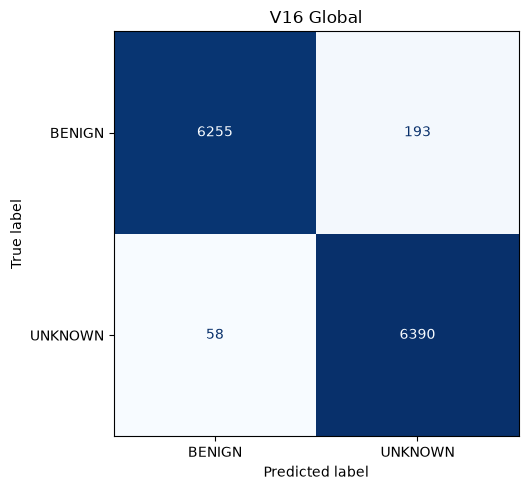

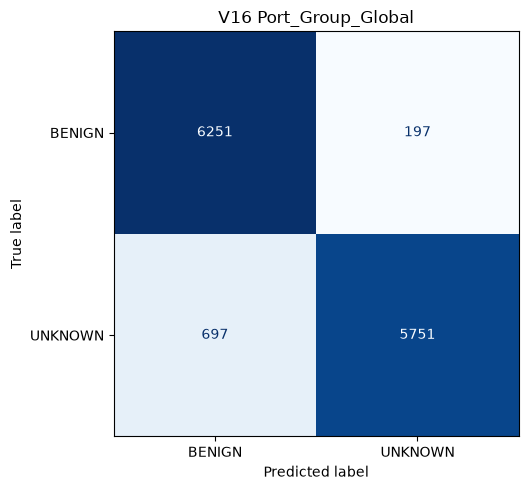

,Method,Accuracy,Precision,Recall,F1,FPR,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,Global,0.9805,0.9707,0.9910,0.9807,0.0299,0.9848,0.9705,6255,193,58,6390
1,Port_Group_Global,0.9307,0.9669,0.8919,0.9279,0.0306,0.9848,0.9705,6251,197,697,5751


,Method,Attack,Samples,Detected,Recall
0,Global,Botnet,736,685,0.9307
1,Global,DoS Slowhttptest,1740,1737,0.9983
2,Global,FTP-Patator,3972,3968,0.9990
3,Port_Group_Global,Botnet,736,46,0.0625
4,Port_Group_Global,DoS Slowhttptest,1740,1737,0.9983
5,Port_Group_Global,FTP-Patator,3972,3968,0.9990


Saved results: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\outputs\results\v16_all_columns_behavioural


In [5]:
scores=reconstruction_mse(models,x_test)
threshold_global=calibration['global_threshold']
threshold_local=local_thresholds(ports(test),calibration)
predictions={'Global':(scores>threshold_global).astype(int),
             'Port_Group_Global':(scores>threshold_local).astype(int)}
metrics=[]; per_attack=[]
for name,pred in predictions.items():
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    metrics.append({'Method':name,'Accuracy':accuracy_score(y_true,pred),
                    'Precision':precision_score(y_true,pred,zero_division=0),
                    'Recall':recall_score(y_true,pred,zero_division=0),
                    'F1':f1_score(y_true,pred,zero_division=0),
                    'FPR':fp/(fp+tn) if fp+tn else np.nan,
                    'ROC_AUC':roc_auc_score(y_true,scores),
                    'PR_AUC':average_precision_score(y_true,scores),
                    'TN':tn,'FP':fp,'FN':fn,'TP':tp})
    for attack in sorted(set(labels)-{'BENIGN'}):
        mask=labels==attack
        per_attack.append({'Method':name,'Attack':attack,'Samples':int(mask.sum()),
                           'Detected':int(pred[mask].sum()),'Recall':float(pred[mask].mean())})
    fig,ax=plt.subplots(figsize=(6,5))
    ConfusionMatrixDisplay.from_predictions(y_true,pred,labels=[0,1],
        display_labels=['BENIGN','UNKNOWN'],cmap='Blues',values_format='d',colorbar=False,ax=ax)
    ax.set_title(f'V16 {name}'); fig.tight_layout()
    fig.savefig(RESULTS_DIR/f'confusion_matrix_{name}.png',dpi=160)
    plt.show()
metrics_df=pd.DataFrame(metrics); per_attack_df=pd.DataFrame(per_attack)
display(metrics_df.round(4)); display(per_attack_df.round(4))
metrics_df.to_csv(RESULTS_DIR/'metrics.csv',index=False)
per_attack_df.to_csv(RESULTS_DIR/'per_attack.csv',index=False)
pd.DataFrame({'Label':labels,'Score':scores,'Global_Threshold':threshold_global,
              'Local_Threshold':threshold_local,
              **{name+'_pred':pred for name,pred in predictions.items()}}).to_csv(
              RESULTS_DIR/'predictions.csv',index=False)
print('Saved results:',RESULTS_DIR)


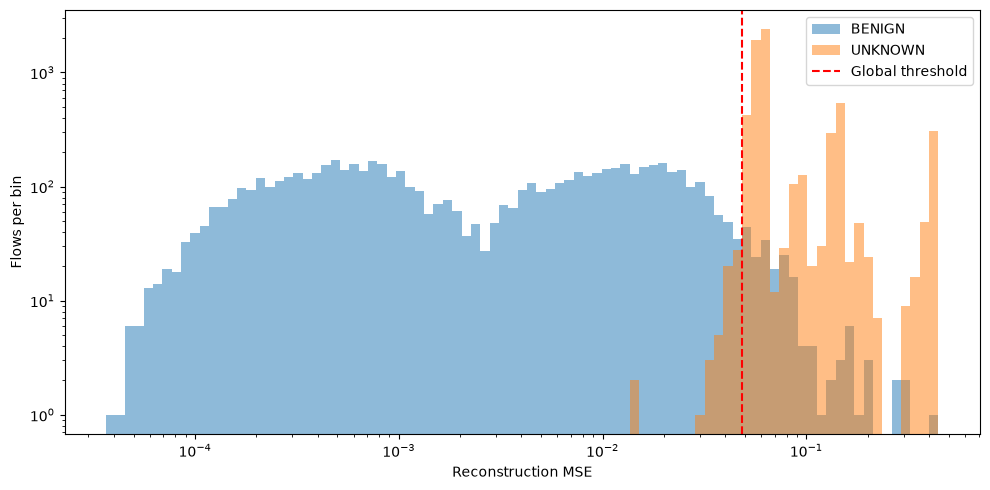

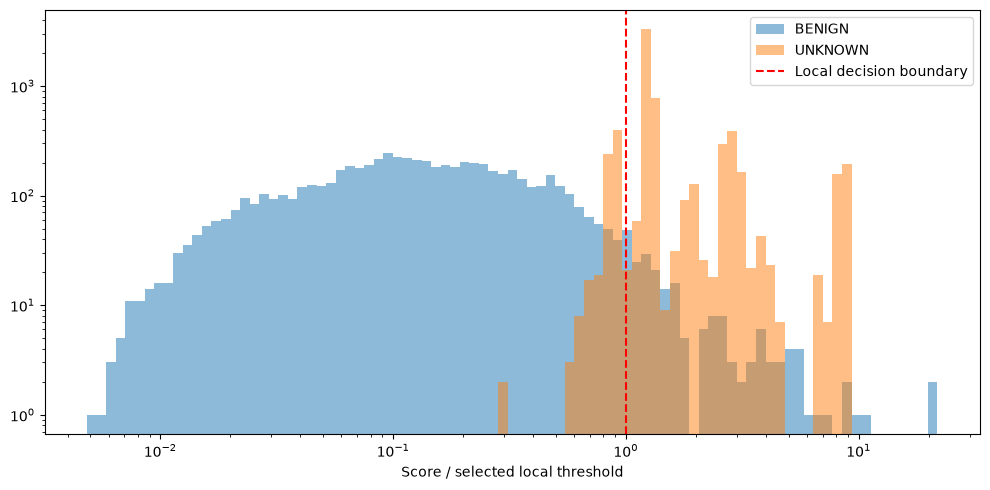

In [6]:
# Global score histogram; for local thresholds the normalized ratio plot is more faithful.
benign_scores=scores[y_true==0]; attack_scores=scores[y_true==1]
positive=scores[np.isfinite(scores)&(scores>0)]
if len(positive):
    bins=np.geomspace(positive.min(),positive.max(),90)
    fig,ax=plt.subplots(figsize=(10,5))
    ax.hist(benign_scores,bins=bins,alpha=.5,label='BENIGN')
    ax.hist(attack_scores,bins=bins,alpha=.5,label='UNKNOWN')
    ax.axvline(threshold_global,linestyle='--',color='red',label='Global threshold')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.legend()
    ax.set_xlabel('Reconstruction MSE'); ax.set_ylabel('Flows per bin')
    fig.tight_layout(); fig.savefig(RESULTS_DIR/'reconstruction_histogram.png',dpi=160)
    plt.show()
ratio=scores/np.maximum(threshold_local,np.finfo(float).eps)
positive_ratio=ratio[np.isfinite(ratio)&(ratio>0)]
if len(positive_ratio):
    fig,ax=plt.subplots(figsize=(10,5))
    bins=np.geomspace(positive_ratio.min(),positive_ratio.max(),90)
    ax.hist(ratio[y_true==0],bins=bins,alpha=.5,label='BENIGN')
    ax.hist(ratio[y_true==1],bins=bins,alpha=.5,label='UNKNOWN')
    ax.axvline(1,color='red',linestyle='--',label='Local decision boundary')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.legend()
    ax.set_xlabel('Score / selected local threshold')
    fig.tight_layout(); fig.savefig(RESULTS_DIR/'local_threshold_ratio_histogram.png',dpi=160)
    plt.show()
